In [1]:
# ============================================================
# LABORATORIO DE COMPETENCIA Y MICROESTRUCTURA DEL MERCADO P2P
# Notebook 01: Diagnóstico de datos
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración general
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [4]:
# ============================================================
# 1. CARGA DE DATOS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Ruta al CSV del proyecto Dashboard-Economico2
archivo = Path("../data/detalle_binance3.csv")

# Verificar existencia del archivo
if not archivo.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {archivo.resolve()}"
    )

# Cargar base
df = pd.read_csv(
    archivo,
    sep=";",
    encoding="utf-8"
)

print(f"Dimensiones de la base: {df.shape}")

display(df.head())

Dimensiones de la base: (602106, 7)


,Precio,Vendedor,Limite_min,Limite_max,Disponible,Timestamp,Tipo
0,12.8100,MessidelUSDT,55,138390,95.2400,11/9/2025 18:00,BUY
1,12.8800,Criptoren-10K,55,138390,334.4700,11/9/2025 18:00,BUY
2,12.8800,Schutmaat,1000,13000,628.1800,11/9/2025 18:00,BUY
3,12.8900,Venom_Sjzb,500,200000,507.5500,11/9/2025 18:00,BUY
4,12.8900,Gypsi12,2500,30000,953.9200,11/9/2025 18:00,BUY


In [5]:
# ============================================================
# 2. PREPARACIÓN DE VARIABLES
# ============================================================

# Convertir Timestamp a formato datetime
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    dayfirst=True,
    errors="coerce"
)

# Convertir variables numéricas
columnas_numericas = [
    "Precio",
    "Limite_min",
    "Limite_max",
    "Disponible"
]

for col in columnas_numericas:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Eliminar registros sin Timestamp válido
df = df.dropna(subset=["Timestamp"])

# Ordenar cronológicamente
df = df.sort_values("Timestamp").reset_index(drop=True)

print("Base preparada.")
print(f"Registros: {len(df):,}")
print(f"Fecha inicial: {df['Timestamp'].min()}")
print(f"Fecha final: {df['Timestamp'].max()}")

display(df.head())

Base preparada.
Registros: 602,106
Fecha inicial: 2025-09-11 18:00:00
Fecha final: 2026-11-18 14:30:00


,Precio,Vendedor,Limite_min,Limite_max,Disponible,Timestamp,Tipo
0,12.8100,MessidelUSDT,55,138390,95.2400,2025-09-11 18:00:00,BUY
1,12.0000,GermanBol,35,207585,"1,901.1200",2025-09-11 18:00:00,SELL
2,12.0000,Te_Gateo,35,35000,204.2900,2025-09-11 18:00:00,SELL
3,12.0000,CRIPTO-SEGURO-BOLIVA,50,207585,"13,090.3800",2025-09-11 18:00:00,SELL
4,12.0000,Claryvidad,100,138390,300.0000,2025-09-11 18:00:00,SELL


In [6]:
# ============================================================
# 3. DIAGNÓSTICO DE LA ESTRUCTURA TEMPORAL
# ============================================================

# Número de snapshots únicos
snapshots = (
    df["Timestamp"]
    .drop_duplicates()
    .sort_values()
)

print("Número de snapshots:", len(snapshots))

# Diferencia temporal entre snapshots consecutivos
intervalos = snapshots.diff().dropna()

print("\nDistribución de intervalos entre snapshots:")

display(
    intervalos.value_counts()
    .sort_index()
    .head(20)
)

# Estadísticas descriptivas de los intervalos
print("\nEstadísticas de los intervalos:")

display(
    intervalos.describe()
)

Número de snapshots: 1422

Distribución de intervalos entre snapshots:


Timestamp
0 days 00:01:00    138
0 days 00:02:00      1
0 days 00:03:00      1
0 days 00:10:00      1
0 days 00:32:00      1
0 days 00:33:00      1
0 days 00:35:00      1
0 days 00:54:00      1
0 days 01:00:00      4
0 days 01:08:00      1
0 days 01:10:00      1
0 days 01:24:00      1
0 days 01:25:00      1
0 days 01:32:00      1
0 days 01:33:00      1
0 days 01:36:00      1
0 days 01:40:00      1
0 days 01:41:00      1
0 days 01:42:00      1
0 days 01:43:00      4
Name: count, dtype: int64


Estadísticas de los intervalos:


count                         1421
mean     0 days 07:18:38.508092892
std      0 days 15:45:13.009521980
min                0 days 00:01:00
25%                0 days 02:00:00
50%                0 days 02:57:00
75%                0 days 08:45:00
max               15 days 08:40:00
Name: Timestamp, dtype: object

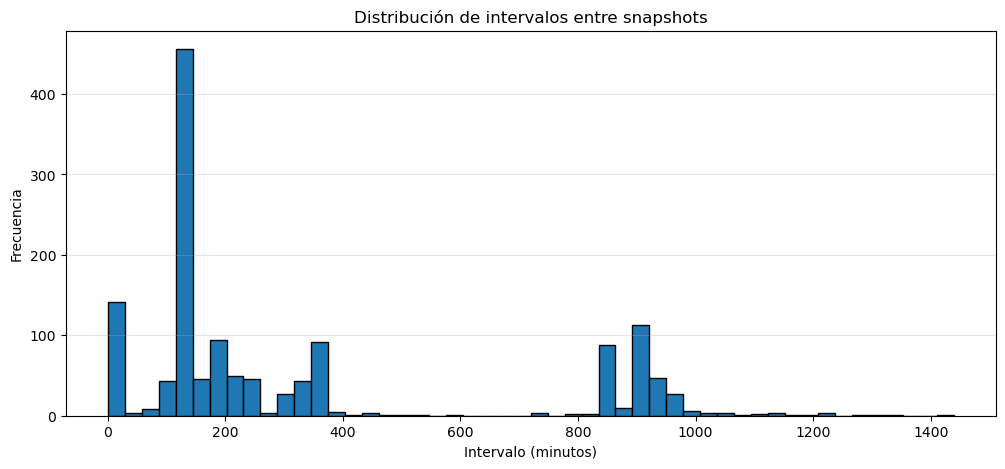

In [7]:
# ============================================================
# 4. DISTRIBUCIÓN DE INTERVALOS ENTRE SNAPSHOTS
# ============================================================

# Convertir intervalos a minutos
intervalos_min = intervalos.dt.total_seconds() / 60

# Limitar visualización a intervalos de hasta 24 horas
intervalos_24h = intervalos_min[intervalos_min <= 1440]

plt.figure(figsize=(12, 5))

plt.hist(
    intervalos_24h,
    bins=50,
    edgecolor="black"
)

plt.title("Distribución de intervalos entre snapshots")
plt.xlabel("Intervalo (minutos)")
plt.ylabel("Frecuencia")

plt.grid(axis="y", alpha=0.3)

plt.show()

Distribución de snapshots diarios:


N_Snapshots
1      23
2      28
3     146
4      43
5      16
6      59
7      30
8       5
9       4
13      1
Name: count, dtype: int64

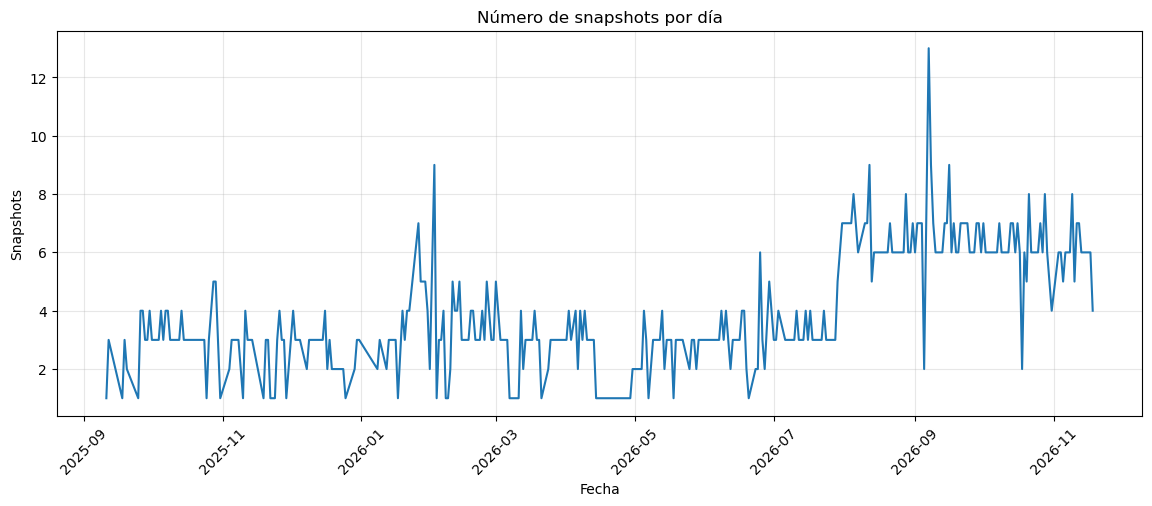

In [8]:
# ============================================================
# 5. SNAPSHOTS POR DÍA
# ============================================================

snapshots_df = pd.DataFrame({
    "Timestamp": snapshots
})

snapshots_df["Fecha"] = (
    snapshots_df["Timestamp"].dt.date
)

snapshots_por_dia = (
    snapshots_df
    .groupby("Fecha")
    .size()
    .rename("N_Snapshots")
    .reset_index()
)

print("Distribución de snapshots diarios:")

display(
    snapshots_por_dia["N_Snapshots"]
    .value_counts()
    .sort_index()
)

# Gráfico de snapshots diarios
plt.figure(figsize=(14, 5))

plt.plot(
    snapshots_por_dia["Fecha"],
    snapshots_por_dia["N_Snapshots"]
)

plt.title("Número de snapshots por día")
plt.xlabel("Fecha")
plt.ylabel("Snapshots")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [9]:
# ============================================================
# 6. FRECUENCIA DE SCRAPING POR MES
# ============================================================

snapshots_df["Timestamp"] = pd.to_datetime(
    snapshots_df["Timestamp"]
)

snapshots_df["Mes"] = (
    snapshots_df["Timestamp"].dt.to_period("M")
)

# Número de días observados por mes
dias_observados = (
    snapshots_df
    .groupby("Mes")["Fecha"]
    .nunique()
)

# Número de snapshots por mes
snapshots_mes = (
    snapshots_df
    .groupby("Mes")
    .size()
    .rename("Snapshots")
)

# Promedio diario
promedio_diario = (
    snapshots_mes / dias_observados
).rename("Promedio_Diario")

# Consolidar resultados
resumen_temporal = pd.concat(
    [
        snapshots_mes,
        dias_observados.rename("Dias_Observados"),
        promedio_diario
    ],
    axis=1
)

display(resumen_temporal)

,Snapshots,Dias_Observados,Promedio_Diario
Mes,,,
2025-09,29,11,2.6364
2025-10,94,30,3.1333
2025-11,51,20,2.5500
2025-12,63,23,2.7391
2026-01,63,18,3.5000
2026-02,93,27,3.4444
2026-03,75,26,2.8846
2026-04,43,15,2.8667
2026-05,71,26,2.7308


In [10]:
# ============================================================
# 7. ESTRUCTURA DEL MERCADO POR SNAPSHOT
# ============================================================

# Número de vendedores únicos por snapshot y tipo
estructura = (
    df.groupby(["Timestamp", "Tipo"])
      .agg(
          N_Anuncios=("Vendedor", "count"),
          N_Vendedores=("Vendedor", "nunique"),
          Precio_Medio=("Precio", "mean"),
          Precio_Mediano=("Precio", "median"),
          Disponibilidad_Total=("Disponible", "sum")
      )
      .reset_index()
)

display(estructura.head(10))

,Timestamp,Tipo,N_Anuncios,N_Vendedores,Precio_Medio,Precio_Mediano,Disponibilidad_Total
0,2025-09-11 18:00:00,BUY,117,96,14.0781,13.1000,"466,956.7900"
1,2025-09-11 18:00:00,SELL,304,249,11.2629,12.1250,"2,226,010.1400"
2,2025-09-12 10:00:00,BUY,171,128,13.5065,12.8500,"746,783.7600"
3,2025-09-12 10:00:00,SELL,272,226,11.1436,12.0000,"1,802,103.1300"
4,2025-09-12 14:11:00,BUY,210,160,13.3916,12.8100,"1,055,280.9500"
5,2025-09-12 14:11:00,SELL,219,192,10.7711,11.5000,"1,244,851.5100"
6,2025-09-12 18:00:00,BUY,155,125,13.6757,12.8800,"615,714.4500"
7,2025-09-12 18:00:00,SELL,262,223,11.0888,12.0000,"1,725,644.7300"
8,2025-09-18 17:30:00,BUY,145,117,13.7558,12.8000,"607,091.8000"
9,2025-09-18 17:30:00,SELL,255,208,11.0703,12.1000,"1,852,922.7400"


In [11]:
# ============================================================
# 8. RESUMEN DE LA ESTRUCTURA DEL MERCADO
# ============================================================

resumen_estructura = (
    estructura.groupby("Tipo")
    .agg(
        Snapshots=("Timestamp", "nunique"),
        Anuncios_Promedio=("N_Anuncios", "mean"),
        Vendedores_Promedio=("N_Vendedores", "mean"),
        Precio_Medio=("Precio_Medio", "mean"),
        Disponibilidad_Promedio=("Disponibilidad_Total", "mean")
    )
)

display(resumen_estructura)

,Snapshots,Anuncios_Promedio,Vendedores_Promedio,Precio_Medio,Disponibilidad_Promedio
Tipo,,,,,
BUY,1312,175.0297,104.8110,11.7745,"1,168,561.9330"
SELL,1319,282.3859,193.5118,9.9565,"4,302,793.3853"


In [12]:
# ============================================================
# 9. DISTRIBUCIÓN DE PRECIOS POR SNAPSHOT
# ============================================================

precios_mercado = (
    df.groupby(["Timestamp", "Tipo"])
      .agg(
          Precio_Min=("Precio", "min"),
          Precio_Max=("Precio", "max"),
          Precio_Mediano=("Precio", "median"),
          Q25=("Precio", lambda x: x.quantile(0.25)),
          Q75=("Precio", lambda x: x.quantile(0.75)),
          Precio_Medio=("Precio", "mean"),
          N_Anuncios=("Precio", "count")
      )
      .reset_index()
)

display(precios_mercado.head(10))

,Timestamp,Tipo,Precio_Min,Precio_Max,Precio_Mediano,Q25,Q75,Precio_Medio,N_Anuncios
0,2025-09-11 18:00:00,BUY,12.8100,20.7800,13.1000,13.0000,14.3800,14.0781,117
1,2025-09-11 18:00:00,SELL,6.0900,14.7000,12.1250,10.5000,12.6000,11.2629,304
2,2025-09-12 10:00:00,BUY,12.7700,20.7800,12.8500,12.8100,13.1250,13.5065,171
3,2025-09-12 10:00:00,SELL,6.0900,14.7000,12.0000,10.1750,12.6400,11.1436,272
4,2025-09-12 14:11:00,BUY,12.6900,20.7800,12.8100,12.7400,13.0975,13.3916,210
5,2025-09-12 14:11:00,SELL,6.0900,14.7000,11.5000,10.0000,12.4000,10.7711,219
6,2025-09-12 18:00:00,BUY,12.7000,20.7800,12.8800,12.7700,13.5000,13.6757,155
7,2025-09-12 18:00:00,SELL,6.0900,14.7000,12.0000,10.1000,12.5700,11.0888,262
8,2025-09-18 17:30:00,BUY,12.6400,20.7000,12.8000,12.7000,13.4000,13.7558,145
9,2025-09-18 17:30:00,SELL,6.1000,14.7000,12.1000,10.1000,12.5000,11.0703,255


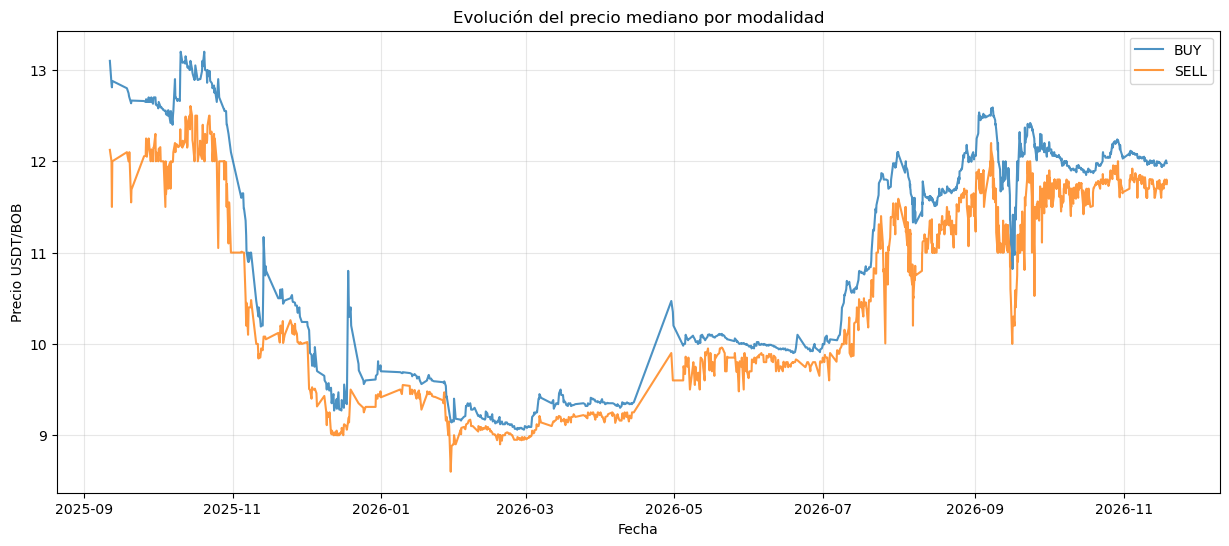

In [13]:
# ============================================================
# 10. EVOLUCIÓN DEL PRECIO MEDIANO
# ============================================================

plt.figure(figsize=(15, 6))

for tipo in precios_mercado["Tipo"].unique():

    datos = precios_mercado[
        precios_mercado["Tipo"] == tipo
    ]

    plt.plot(
        datos["Timestamp"],
        datos["Precio_Mediano"],
        label=tipo,
        alpha=0.8
    )

plt.title("Evolución del precio mediano por modalidad")
plt.xlabel("Fecha")
plt.ylabel("Precio USDT/BOB")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
# ============================================================
# 11. SPREAD ENTRE MODALIDADES BUY Y SELL
# ============================================================

precios_wide = (
    precios_mercado
    .pivot(
        index="Timestamp",
        columns="Tipo",
        values="Precio_Mediano"
    )
    .sort_index()
)

# Spread entre medianas
precios_wide["Spread"] = (
    precios_wide["BUY"] - precios_wide["SELL"]
)

display(precios_wide.head())

# Estadísticas descriptivas
display(
    precios_wide[
        ["BUY", "SELL", "Spread"]
    ].describe()
)

Tipo,BUY,SELL,Spread
Timestamp,,,
2025-09-11 18:00:00,13.1000,12.1250,0.9750
2025-09-12 10:00:00,12.8500,12.0000,0.8500
2025-09-12 14:11:00,12.8100,11.5000,1.3100
2025-09-12 18:00:00,12.8800,12.0000,0.8800
2025-09-18 17:30:00,12.8000,12.1000,0.7000


Tipo,BUY,SELL,Spread
count,"1,312.0000","1,319.0000","1,209.0000"
mean,11.1016,10.6961,0.3921
std,1.2248,1.1054,0.2568
min,9.0600,8.6000,0.0900
25%,9.9500,9.6875,0.2000
50%,11.6700,11.0600,0.3100
75%,12.0525,11.7000,0.5400
max,13.2000,12.6050,1.8500


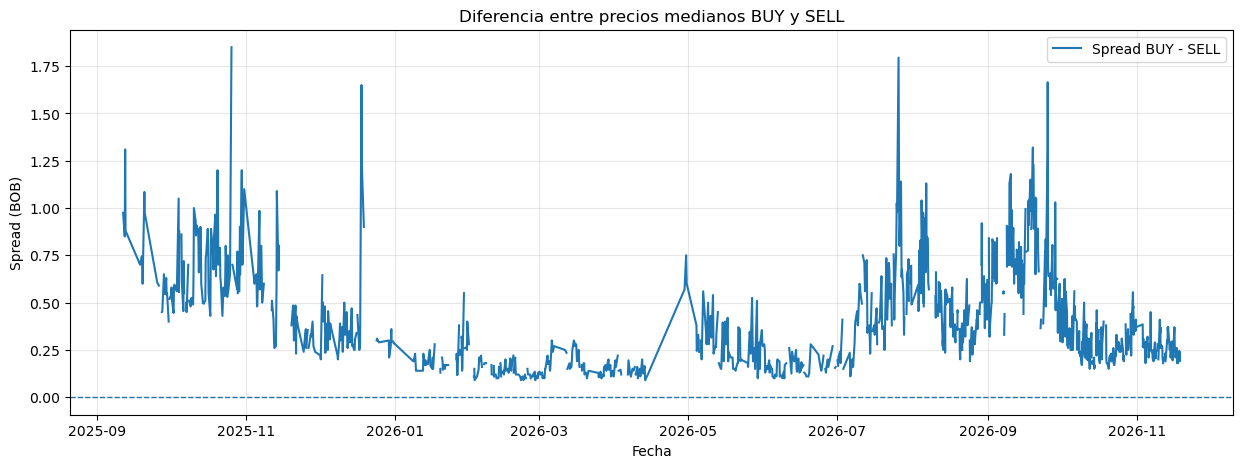

In [15]:
# ============================================================
# 12. EVOLUCIÓN DEL SPREAD
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    precios_wide.index,
    precios_wide["Spread"],
    label="Spread BUY - SELL"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Diferencia entre precios medianos BUY y SELL")
plt.xlabel("Fecha")
plt.ylabel("Spread (BOB)")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [16]:
# ============================================================
# 13. CORRELACIÓN CONTEMPORÁNEA
# ============================================================

correlacion = precios_wide[
    ["BUY", "SELL"]
].corr()

display(correlacion)

Tipo,BUY,SELL
Tipo,,
BUY,1.0000,0.9812
SELL,0.9812,1.0000


In [17]:
# ============================================================
# 14. VARIACIONES DE PRECIOS
# ============================================================

precios_wide = precios_wide.sort_index()

# Variaciones absolutas
precios_wide["Delta_BUY"] = precios_wide["BUY"].diff()
precios_wide["Delta_SELL"] = precios_wide["SELL"].diff()

# Variaciones porcentuales
precios_wide["Pct_BUY"] = precios_wide["BUY"].pct_change() * 100
precios_wide["Pct_SELL"] = precios_wide["SELL"].pct_change() * 100

display(
    precios_wide[
        ["BUY", "SELL", "Delta_BUY", "Delta_SELL"]
    ].head(10)
)

C:\Users\sergio.garnica\AppData\Local\Temp\ipykernel_12668\1170312099.py:12: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  precios_wide["Pct_BUY"] = precios_wide["BUY"].pct_change() * 100
C:\Users\sergio.garnica\AppData\Local\Temp\ipykernel_12668\1170312099.py:13: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  precios_wide["Pct_SELL"] = precios_wide["SELL"].pct_change() * 100


Tipo,BUY,SELL,Delta_BUY,Delta_SELL
Timestamp,,,,
2025-09-11 18:00:00,13.1000,12.1250,NaN,NaN
2025-09-12 10:00:00,12.8500,12.0000,-0.2500,-0.1250
2025-09-12 14:11:00,12.8100,11.5000,-0.0400,-0.5000
2025-09-12 18:00:00,12.8800,12.0000,0.0700,0.5000
2025-09-18 17:30:00,12.8000,12.1000,-0.0800,0.1000
2025-09-19 10:00:00,12.7450,12.0000,-0.0550,-0.1000
2025-09-19 14:00:00,12.7150,12.0000,-0.0300,0.0000
2025-09-19 17:30:00,12.7000,12.1000,-0.0150,0.1000
2025-09-20 11:04:00,12.6350,11.5500,-0.0650,-0.5500


In [18]:
# ============================================================
# 15. CORRELACIÓN ENTRE CAMBIOS DE PRECIOS
# ============================================================

correlacion_cambios = precios_wide[
    ["Delta_BUY", "Delta_SELL"]
].corr()

display(correlacion_cambios)

Tipo,Delta_BUY,Delta_SELL
Tipo,,
Delta_BUY,1.0000,0.2574
Delta_SELL,0.2574,1.0000


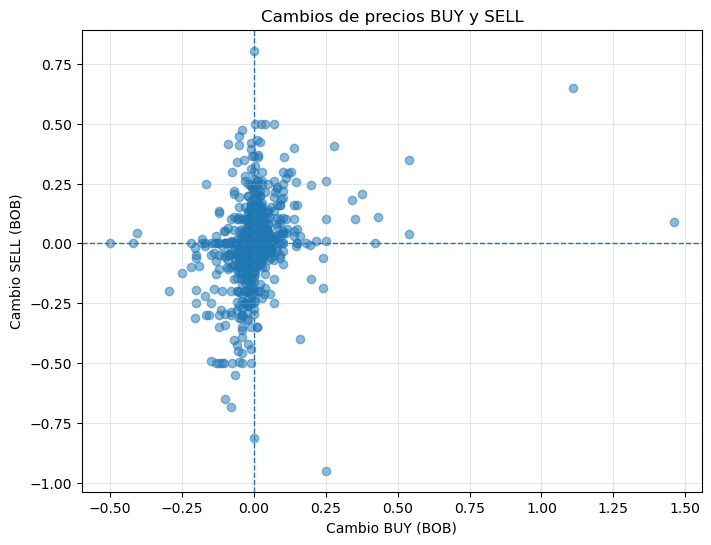

In [19]:
# ============================================================
# 16. DISPERSIÓN DE CAMBIOS DE PRECIOS
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    precios_wide["Delta_BUY"],
    precios_wide["Delta_SELL"],
    alpha=0.5
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Cambios de precios BUY y SELL")
plt.xlabel("Cambio BUY (BOB)")
plt.ylabel("Cambio SELL (BOB)")

plt.grid(alpha=0.3)
plt.show()

In [20]:
# ============================================================
# 17. INTERVALOS ENTRE OBSERVACIONES DE PRECIOS
# ============================================================

# Trabajamos con los snapshots donde existen ambas modalidades
precios_wide = precios_wide.sort_index().copy()

# Tiempo transcurrido entre observaciones
precios_wide["Intervalo_horas"] = (
    precios_wide.index.to_series()
    .diff()
    .dt.total_seconds()
    .div(3600)
)

# Cambios de precios
precios_wide["Delta_BUY"] = (
    precios_wide["BUY"].diff()
)

precios_wide["Delta_SELL"] = (
    precios_wide["SELL"].diff()
)

# Cambios porcentuales
precios_wide["Pct_BUY"] = (
    precios_wide["BUY"].pct_change(fill_method=None) * 100
)

precios_wide["Pct_SELL"] = (
    precios_wide["SELL"].pct_change(fill_method=None) * 100
)

display(
    precios_wide[
        [
            "BUY",
            "SELL",
            "Intervalo_horas",
            "Delta_BUY",
            "Delta_SELL"
        ]
    ].head(15)
)

Tipo,BUY,SELL,Intervalo_horas,Delta_BUY,Delta_SELL
Timestamp,,,,,
2025-09-11 18:00:00,13.1000,12.1250,NaN,NaN,NaN
2025-09-12 10:00:00,12.8500,12.0000,16.0000,-0.2500,-0.1250
2025-09-12 14:11:00,12.8100,11.5000,4.1833,-0.0400,-0.5000
2025-09-12 18:00:00,12.8800,12.0000,3.8167,0.0700,0.5000
2025-09-18 17:30:00,12.8000,12.1000,143.5000,-0.0800,0.1000
2025-09-19 10:00:00,12.7450,12.0000,16.5000,-0.0550,-0.1000
2025-09-19 14:00:00,12.7150,12.0000,4.0000,-0.0300,0.0000
2025-09-19 17:30:00,12.7000,12.1000,3.5000,-0.0150,0.1000
2025-09-20 11:04:00,12.6350,11.5500,17.5667,-0.0650,-0.5500


In [21]:
# ============================================================
# 18. CORRELACIÓN DE CAMBIOS SEGÚN INTERVALO TEMPORAL
# ============================================================

# Clasificar los intervalos
bins = [0, 2, 4, 8, 12, 24, 48, np.inf]

labels = [
    "0-2 horas",
    "2-4 horas",
    "4-8 horas",
    "8-12 horas",
    "12-24 horas",
    "24-48 horas",
    "Más de 48 horas"
]

precios_wide["Grupo_Intervalo"] = pd.cut(
    precios_wide["Intervalo_horas"],
    bins=bins,
    labels=labels,
    right=True
)

# Calcular correlaciones por grupo
resultados_corr = []

for grupo, datos in precios_wide.groupby(
    "Grupo_Intervalo",
    observed=True
):

    muestra = datos[
        ["Delta_BUY", "Delta_SELL"]
    ].dropna()

    resultados_corr.append({
        "Intervalo": grupo,
        "Observaciones": len(muestra),
        "Correlacion": (
            muestra["Delta_BUY"].corr(
                muestra["Delta_SELL"]
            )
            if len(muestra) >= 3
            else np.nan
        )
    })

correlacion_intervalos = pd.DataFrame(
    resultados_corr
)

display(correlacion_intervalos)

,Intervalo,Observaciones,Correlacion
0,0-2 horas,425,0.3982
1,2-4 horas,206,0.1758
2,4-8 horas,162,0.2564
3,8-12 horas,5,0.9414
4,12-24 horas,276,0.1952
5,24-48 horas,3,0.5690
6,Más de 48 horas,18,0.7663


In [22]:
# ============================================================
# 19. CONSTRUIR MUESTRA CON PRECIOS BUY Y SELL COMUNES
# ============================================================

# Conservar timestamps donde existen ambas modalidades
precios_comunes = (
    precios_wide[["BUY", "SELL"]]
    .dropna()
    .sort_index()
    .copy()
)

# Intervalo entre observaciones comunes
precios_comunes["Intervalo_horas"] = (
    precios_comunes.index.to_series()
    .diff()
    .dt.total_seconds()
    / 3600
)

# Variaciones de precios
precios_comunes["Delta_BUY"] = (
    precios_comunes["BUY"].diff()
)

precios_comunes["Delta_SELL"] = (
    precios_comunes["SELL"].diff()
)

# Eliminar primera observación, que no tiene variación
precios_comunes = precios_comunes.dropna(
    subset=["Delta_BUY", "Delta_SELL", "Intervalo_horas"]
)

display(precios_comunes.head(15))

Tipo,BUY,SELL,Intervalo_horas,Delta_BUY,Delta_SELL
Timestamp,,,,,
2025-09-12 10:00:00,12.8500,12.0000,16.0000,-0.2500,-0.1250
2025-09-12 14:11:00,12.8100,11.5000,4.1833,-0.0400,-0.5000
2025-09-12 18:00:00,12.8800,12.0000,3.8167,0.0700,0.5000
2025-09-18 17:30:00,12.8000,12.1000,143.5000,-0.0800,0.1000
2025-09-19 10:00:00,12.7450,12.0000,16.5000,-0.0550,-0.1000
2025-09-19 14:00:00,12.7150,12.0000,4.0000,-0.0300,0.0000
2025-09-19 17:30:00,12.7000,12.1000,3.5000,-0.0150,0.1000
2025-09-20 11:04:00,12.6350,11.5500,17.5667,-0.0650,-0.5500
2025-09-20 14:21:00,12.6650,11.6900,3.2833,0.0300,0.1400


In [23]:
# ============================================================
# 20. CORRELACIÓN DE CAMBIOS EN MUESTRA COMÚN
# ============================================================

bins = [0, 2, 4, 8, 12, 24, 48, np.inf]

labels = [
    "0-2 horas",
    "2-4 horas",
    "4-8 horas",
    "8-12 horas",
    "12-24 horas",
    "24-48 horas",
    "Más de 48 horas"
]

precios_comunes["Grupo_Intervalo"] = pd.cut(
    precios_comunes["Intervalo_horas"],
    bins=bins,
    labels=labels
)

resultados_corr = []

for grupo, datos in precios_comunes.groupby(
    "Grupo_Intervalo",
    observed=True
):

    resultados_corr.append({
        "Intervalo": grupo,
        "Observaciones": len(datos),
        "Correlacion": datos[
            ["Delta_BUY", "Delta_SELL"]
        ].corr().iloc[0, 1]
    })

correlacion_intervalos = pd.DataFrame(
    resultados_corr
)

display(correlacion_intervalos)

,Intervalo,Observaciones,Correlacion
0,0-2 horas,426,0.3982
1,2-4 horas,239,0.2151
2,4-8 horas,175,0.2657
3,8-12 horas,18,-0.1483
4,12-24 horas,317,0.2073
5,24-48 horas,6,0.4550
6,Más de 48 horas,27,0.7589


In [24]:
# ============================================================
# 21. IDENTIFICAR TIMESTAMPS DE CAPTURA POR MODALIDAD
# ============================================================

capturas_tipo = (
    df.groupby("Tipo")["Timestamp"]
    .nunique()
)

display(capturas_tipo)

Tipo
BUY     1312
SELL    1319
Name: Timestamp, dtype: int64

In [25]:
# ============================================================
# 22. CONSTRUIR TIMESTAMPS DE REFERENCIA BUY
# ============================================================

# Capturas únicas BUY
capturas_buy = (
    df.loc[df["Tipo"] == "BUY", ["Timestamp"]]
    .drop_duplicates()
    .sort_values("Timestamp")
    .rename(
        columns={"Timestamp": "Timestamp_Snapshot"}
    )

)

display(capturas_buy.head(10))

,Timestamp_Snapshot
0,2025-09-11 18:00:00
642,2025-09-12 10:00:00
1080,2025-09-12 14:11:00
1503,2025-09-12 18:00:00
1912,2025-09-18 17:30:00
2316,2025-09-19 10:00:00
2738,2025-09-19 14:00:00
3175,2025-09-19 17:30:00
3603,2025-09-20 11:04:00
4005,2025-09-20 14:21:00


In [26]:
# ============================================================
# 23. ASIGNAR SELL AL SNAPSHOT BUY
# ============================================================

from pandas import merge_asof

# Separar modalidades
df_buy = df[df["Tipo"] == "BUY"].copy()

df_sell = df[df["Tipo"] == "SELL"].copy()

# BUY: timestamp de referencia es su propio Timestamp
df_buy["Timestamp_Snapshot"] = df_buy["Timestamp"]

# SELL: asociar al BUY inmediatamente anterior
df_sell = merge_asof(
    df_sell.sort_values("Timestamp"),
    capturas_buy.sort_values("Timestamp_Snapshot"),
    left_on="Timestamp",
    right_on="Timestamp_Snapshot",
    direction="backward",
    tolerance=pd.Timedelta("5min")
)

# Revisar SELL no asociados
sell_no_asociados = df_sell[
    df_sell["Timestamp_Snapshot"].isna()
]

print(
    "SELL no asociados:",
    len(sell_no_asociados)
)

# Conservar solo SELL asociados
df_sell_asociado = df_sell.dropna(
    subset=["Timestamp_Snapshot"]
)

# Unir BUY y SELL
df_alineado = pd.concat(
    [
        df_buy,
        df_sell_asociado
    ],
    ignore_index=True
)

# Ordenar
df_alineado = df_alineado.sort_values(
    ["Timestamp_Snapshot", "Tipo", "Timestamp"]
).reset_index(drop=True)

display(df_alineado.head(15))

SELL no asociados: 229


,Precio,Vendedor,Limite_min,Limite_max,Disponible,Timestamp,Tipo,Timestamp_Snapshot
0,12.8100,MessidelUSDT,55,138390,95.2400,2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
1,13.5400,VelozFX,50,207585,"2,965.6400",2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
2,13.5100,JU727-2,35,1800,188.5100,2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
3,13.5000,GermanBol,35,207585,500.0000,2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
4,13.5000,JPizo,300,30000,229.0200,2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
5,13.5000,Eduardo-BTC,500,207585,"23,766.1000",2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
6,13.5000,Romero Fx,10000,207585,"3,769.5400",2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
7,13.5000,USDCochabamba,100,200000,"17,478.0400",2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
8,13.5000,EDWIN_TRADER_xD,100,207585,"30,851.7200",2025-09-11 18:00:00,BUY,2025-09-11 18:00:00
9,13.5000,Oncsur,55,1300,112.4800,2025-09-11 18:00:00,BUY,2025-09-11 18:00:00


In [27]:
# ============================================================
# 24. VALIDAR ALINEACIÓN BUY-SELL
# ============================================================

# Diferencia temporal entre captura original y snapshot asignado
df_alineado["Diferencia_Minutos"] = (
    df_alineado["Timestamp"]
    - df_alineado["Timestamp_Snapshot"]
).dt.total_seconds() / 60

# Resumen por modalidad
resumen_alineacion = (
    df_alineado.groupby("Tipo")
    .agg(
        Registros=("Timestamp", "count"),
        Snapshots=("Timestamp_Snapshot", "nunique"),
        Diferencia_Minutos_Media=(
            "Diferencia_Minutos", "mean"
        ),
        Diferencia_Minutos_Max=(
            "Diferencia_Minutos", "max"
        )
    )
)

display(resumen_alineacion)

,Registros,Snapshots,Diferencia_Minutos_Media,Diferencia_Minutos_Max
Tipo,,,,
BUY,229639,1312,0.0000,0.0000
SELL,372238,1295,0.0787,2.0000


In [28]:
# ============================================================
# 25. REVISAR CASO 26-09-2025
# ============================================================

fecha_revision = pd.Timestamp("2025-09-26")

display(
    df_alineado[
        df_alineado["Timestamp_Snapshot"].dt.date
        == fecha_revision.date()
    ][
        [
            "Timestamp",
            "Timestamp_Snapshot",
            "Tipo",
            "Vendedor",
            "Precio",
            "Diferencia_Minutos"
        ]
    ].head(30)
)

,Timestamp,Timestamp_Snapshot,Tipo,Vendedor,Precio,Diferencia_Minutos
4599,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,VelozFX,12.6300,0.0000
4600,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,Jose2890trader,12.6200,0.0000
4601,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,ErickVM,12.6200,0.0000
4602,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,OrellanaFX,12.6200,0.0000
4603,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,_CryptoCambista_,12.6200,0.0000
4604,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,crip_jhor,12.6100,0.0000
4605,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,A-RJrL,12.6100,0.0000
4606,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,ARZ_USDT_P2P,12.6100,0.0000
4607,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,Kuriz_Kuriz,12.6100,0.0000
4608,2025-09-26 10:00:00,2025-09-26 10:00:00,BUY,cripsus69,12.6000,0.0000


In [29]:
# ============================================================
# 26. ESTRUCTURA DE MERCADO POR SNAPSHOT ALINEADO
# ============================================================

estructura_alineada = (
    df_alineado
    .groupby(["Timestamp_Snapshot", "Tipo"])
    .agg(
        N_Anuncios=("Precio", "count"),
        N_Vendedores=("Vendedor", "nunique"),
        Precio_Medio=("Precio", "mean"),
        Precio_Mediano=("Precio", "median"),
        Precio_Min=("Precio", "min"),
        Precio_Max=("Precio", "max"),
        Disponibilidad_Total=("Disponible", "sum")
    )
    .reset_index()
)

display(estructura_alineada.head(10))

,Timestamp_Snapshot,Tipo,N_Anuncios,N_Vendedores,Precio_Medio,Precio_Mediano,Precio_Min,Precio_Max,Disponibilidad_Total
0,2025-09-11 18:00:00,BUY,117,96,14.0781,13.1000,12.8100,20.7800,"466,956.7900"
1,2025-09-11 18:00:00,SELL,304,249,11.2629,12.1250,6.0900,14.7000,"2,226,010.1400"
2,2025-09-12 10:00:00,BUY,171,128,13.5065,12.8500,12.7700,20.7800,"746,783.7600"
3,2025-09-12 10:00:00,SELL,272,226,11.1436,12.0000,6.0900,14.7000,"1,802,103.1300"
4,2025-09-12 14:11:00,BUY,210,160,13.3916,12.8100,12.6900,20.7800,"1,055,280.9500"
5,2025-09-12 14:11:00,SELL,219,192,10.7711,11.5000,6.0900,14.7000,"1,244,851.5100"
6,2025-09-12 18:00:00,BUY,155,125,13.6757,12.8800,12.7000,20.7800,"615,714.4500"
7,2025-09-12 18:00:00,SELL,262,223,11.0888,12.0000,6.0900,14.7000,"1,725,644.7300"
8,2025-09-18 17:30:00,BUY,145,117,13.7558,12.8000,12.6400,20.7000,"607,091.8000"
9,2025-09-18 17:30:00,SELL,255,208,11.0703,12.1000,6.1000,14.7000,"1,852,922.7400"


In [30]:
# ============================================================
# 27. TABLA COMPARATIVA BUY-SELL
# ============================================================

precios_alineados = (
    estructura_alineada
    .pivot(
        index="Timestamp_Snapshot",
        columns="Tipo",
        values="Precio_Mediano"
    )
    .sort_index()
)

# Renombrar columnas
precios_alineados.columns = [
    f"Precio_{col}" for col in precios_alineados.columns
]

# Conservar snapshots donde existen ambas modalidades
precios_alineados = precios_alineados.dropna(
    subset=["Precio_BUY", "Precio_SELL"]
)

display(precios_alineados.head(15))

print(
    "Snapshots con ambas modalidades:",
    len(precios_alineados)
)

,Precio_BUY,Precio_SELL
Timestamp_Snapshot,,
2025-09-11 18:00:00,13.1000,12.1250
2025-09-12 10:00:00,12.8500,12.0000
2025-09-12 14:11:00,12.8100,11.5000
2025-09-12 18:00:00,12.8800,12.0000
2025-09-18 17:30:00,12.8000,12.1000
2025-09-19 10:00:00,12.7450,12.0000
2025-09-19 14:00:00,12.7150,12.0000
2025-09-19 17:30:00,12.7000,12.1000
2025-09-20 11:04:00,12.6350,11.5500


Snapshots con ambas modalidades: 1295


In [31]:
# ============================================================
# 28. SPREAD Y CAMBIOS DE PRECIOS
# ============================================================

precios_alineados["Spread"] = (
    precios_alineados["Precio_BUY"]
    - precios_alineados["Precio_SELL"]
)

# Variaciones absolutas
precios_alineados["Delta_BUY"] = (
    precios_alineados["Precio_BUY"].diff()
)

precios_alineados["Delta_SELL"] = (
    precios_alineados["Precio_SELL"].diff()
)

# Intervalo temporal entre snapshots
precios_alineados["Intervalo_Horas"] = (
    precios_alineados.index.to_series()
    .diff()
    .dt.total_seconds()
    / 3600
)

display(precios_alineados.head(15))

,Precio_BUY,Precio_SELL,Spread,Delta_BUY,Delta_SELL,Intervalo_Horas
Timestamp_Snapshot,,,,,,
2025-09-11 18:00:00,13.1000,12.1250,0.9750,NaN,NaN,NaN
2025-09-12 10:00:00,12.8500,12.0000,0.8500,-0.2500,-0.1250,16.0000
2025-09-12 14:11:00,12.8100,11.5000,1.3100,-0.0400,-0.5000,4.1833
2025-09-12 18:00:00,12.8800,12.0000,0.8800,0.0700,0.5000,3.8167
2025-09-18 17:30:00,12.8000,12.1000,0.7000,-0.0800,0.1000,143.5000
2025-09-19 10:00:00,12.7450,12.0000,0.7450,-0.0550,-0.1000,16.5000
2025-09-19 14:00:00,12.7150,12.0000,0.7150,-0.0300,0.0000,4.0000
2025-09-19 17:30:00,12.7000,12.1000,0.6000,-0.0150,0.1000,3.5000
2025-09-20 11:04:00,12.6350,11.5500,1.0850,-0.0650,-0.5500,17.5667


In [33]:
import pandas as pd
import numpy as np
from pathlib import Path

# Crear carpeta data_clean en el directorio raíz del proyecto para separar datos de notebooks
ruta_clean = Path("../data_clean")
ruta_clean.mkdir(parents=True, exist_ok=True)

def preparar_dataset_vwap(df, tipo_orden='SELL', limite_ffill=2, limite_interp=5, umbral_presencia=0.8):
    """
    1. Calcula el VWAP diario por vendedor y su Precio de Mercado Excluyente (Leave-One-Out).
    2. Estandariza a frecuencia diaria ('D') e imputa fines de semana y feriados cortos.
    3. Segmenta en 2 épocas operativas aislando el vacío de abril 2026.
    """
    df_filtro = df[df['Tipo'] == tipo_orden].copy()
    df_filtro['Fecha'] = df_filtro['Timestamp'].dt.date
    df_filtro['Volumen_Nominal'] = df_filtro['Precio'] * df_filtro['Disponible']
    
    # Totales diarios del mercado para construir el precio excluyente
    mercado_diario = df_filtro.groupby('Fecha').agg(
        Total_Volumen=('Volumen_Nominal', 'sum'),
        Total_Disponible=('Disponible', 'sum')
    )
    
    # Agregación diaria por vendedor
    agrupado = df_filtro.groupby(['Fecha', 'Vendedor']).agg(
        Suma_Volumen=('Volumen_Nominal', 'sum'),
        Suma_Disponible=('Disponible', 'sum')
    ).reset_index()
    
    agrupado['VWAP'] = agrupado['Suma_Volumen'] / agrupado['Suma_Disponible']
    
    # Precio de Mercado Excluyente (excluye al vendedor analizado para evitar endogeneidad)
    agrupado = agrupado.merge(mercado_diario, on='Fecha', how='left')
    agrupado['VWAP_Excluyente'] = (
        (agrupado['Total_Volumen'] - agrupado['Suma_Volumen']) / 
        (agrupado['Total_Disponible'] - agrupado['Suma_Disponible'])
    )
    
    # Pivotar matrices: VWAP individual y VWAP del mercado excluyente
    matriz_vwap = agrupado.pivot(index='Fecha', columns='Vendedor', values='VWAP')
    matriz_excl = agrupado.pivot(index='Fecha', columns='Vendedor', values='VWAP_Excluyente')
    
    matriz_vwap.index = pd.to_datetime(matriz_vwap.index)
    matriz_excl.index = pd.to_datetime(matriz_excl.index)
    
    # Frecuencia diaria estricta y Forward-Fill de fines de semana (máx 2 días)
    df_reg_vwap = matriz_vwap.asfreq('D').ffill(limit=limite_ffill)
    df_reg_excl = matriz_excl.asfreq('D').ffill(limit=limite_ffill)
    
    # Segmentar épocas aislando la segunda quincena de abril 2026
    e1_vwap = df_reg_vwap.loc['2025-09-11':'2026-04-14']
    e2_vwap = df_reg_vwap.loc['2026-05-01':'2026-10-28']
    
    e1_excl = df_reg_excl.loc['2025-09-11':'2026-04-14']
    e2_excl = df_reg_excl.loc['2026-05-01':'2026-10-28']
    
    def filtrar_robustos(df_v, df_e):
        umbral = int(len(df_v) * umbral_presencia)
        # Retener vendedores con al menos 80% de presencia activa en la época
        cols_validas = df_v.dropna(axis=1, thresh=umbral).columns
        
        # Interpolar brechas de feriados (ej. Año Nuevo) y limpiar bordes
        v_clean = df_v[cols_validas].interpolate(method='linear', limit=limite_interp).bfill(limit=2).dropna(axis=1)
        e_clean = df_e[v_clean.columns].interpolate(method='linear', limit=limite_interp).bfill(limit=2)
        return v_clean, e_clean

    e1_v_final, e1_e_final = filtrar_robustos(e1_vwap, e1_excl)
    e2_v_final, e2_e_final = filtrar_robustos(e2_vwap, e2_excl)
    
    return (e1_v_final, e1_e_final), (e2_v_final, e2_e_final)

# Ejecución para SELL y BUY
(e1_sell_vwap, e1_sell_excl), (e2_sell_vwap, e2_sell_excl) = preparar_dataset_vwap(df, tipo_orden='SELL')
(e1_buy_vwap, e1_buy_excl), (e2_buy_vwap, e2_buy_excl) = preparar_dataset_vwap(df, tipo_orden='BUY')

print(f"Época 1 (SELL): {e1_sell_vwap.shape[0]} días, {e1_sell_vwap.shape[1]} vendedores dominantes.")
print(f"Época 2 (SELL): {e2_sell_vwap.shape[0]} días, {e2_sell_vwap.shape[1]} vendedores dominantes.")
print(f"Época 1 (BUY):  {e1_buy_vwap.shape[0]} días, {e1_buy_vwap.shape[1]} vendedores dominantes.")
print(f"Época 2 (BUY):  {e2_buy_vwap.shape[0]} días, {e2_buy_vwap.shape[1]} vendedores dominantes.")

# Exportar las bases limpias a ../data_clean/
e1_sell_vwap.to_csv(ruta_clean / "vwap_diario_epoca1_sell.csv")
e1_sell_excl.to_csv(ruta_clean / "mercado_excl_epoca1_sell.csv")
e2_sell_vwap.to_csv(ruta_clean / "vwap_diario_epoca2_sell.csv")
e2_sell_excl.to_csv(ruta_clean / "mercado_excl_epoca2_sell.csv")

e1_buy_vwap.to_csv(ruta_clean / "vwap_diario_epoca1_buy.csv")
e1_buy_excl.to_csv(ruta_clean / "mercado_excl_epoca1_buy.csv")
e2_buy_vwap.to_csv(ruta_clean / "vwap_diario_epoca2_buy.csv")
e2_buy_excl.to_csv(ruta_clean / "mercado_excl_epoca2_buy.csv")

Época 1 (SELL): 216 días, 48 vendedores dominantes.
Época 2 (SELL): 181 días, 80 vendedores dominantes.
Época 1 (BUY):  216 días, 18 vendedores dominantes.
Época 2 (BUY):  181 días, 34 vendedores dominantes.
